# Datenexploration

## Init

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

# Explorative Datenanalyse (EDA)

In [21]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Make date to index 
df.set_index('date', inplace=True)

# Set daily frequency
df = df.asfreq('d')

# Dateninspektion
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1152 entries, 2016-04-01 to 2019-05-27
Freq: D
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   n_sick    1152 non-null   int64  
 1   calls     1152 non-null   float64
 2   n_duty    1152 non-null   int64  
 3   n_sby     1152 non-null   int64  
 4   sby_need  1152 non-null   float64
 5   dafted    1152 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 63.0 KB


None

,n_sick,calls,n_duty,n_sby,sby_need,dafted
count,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.000000,34.718750,16.335938
std,14.293942,1290.063571,80.086953,0.000000,79.694251,53.394089
min,36.000000,4074.000000,1700.000000,90.000000,0.000000,0.000000
25%,58.000000,6978.000000,1800.000000,90.000000,0.000000,0.000000
50%,68.000000,7932.000000,1800.000000,90.000000,0.000000,0.000000
75%,78.000000,8827.500000,1900.000000,90.000000,12.250000,0.000000
max,119.000000,11850.000000,1900.000000,90.000000,555.000000,465.000000


In [22]:
display(df)

,n_sick,calls,n_duty,n_sby,sby_need,dafted
date,,,,,,
2016-04-01,73,8154.000000,1700,90,4.000000,0.000000
2016-04-02,64,8526.000000,1700,90,70.000000,0.000000
2016-04-03,68,8088.000000,1700,90,0.000000,0.000000
2016-04-04,71,7044.000000,1700,90,0.000000,0.000000
2016-04-05,63,7236.000000,1700,90,0.000000,0.000000
...,...,...,...,...,...,...
2019-05-23,86,8544.000000,1900,90,0.000000,0.000000
2019-05-24,81,8814.000000,1900,90,0.000000,0.000000
2019-05-25,76,9846.000000,1900,90,146.000000,56.000000


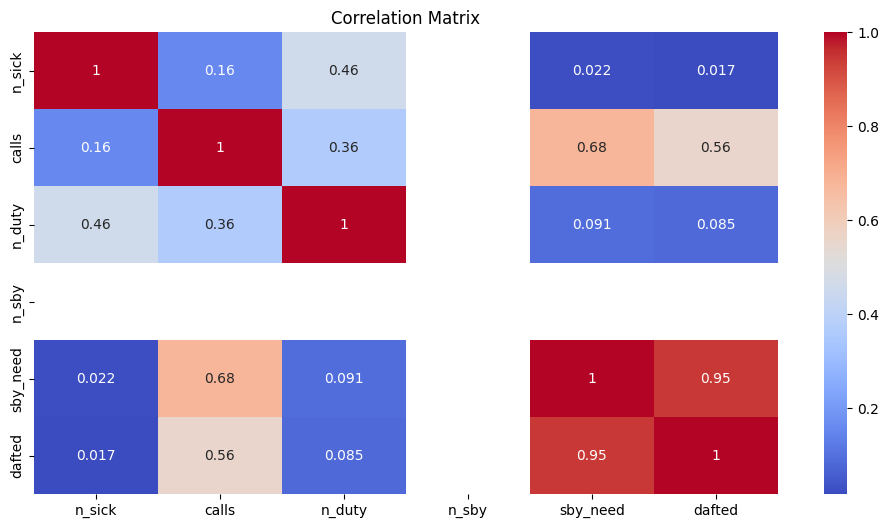

In [23]:
# Visualisierungen
#plt.figure(figsize=(12, 6))
#sns.histplot(df['n_sick'], kde=True)
#plt.title('Distribution of n_sick')
#plt.show()

#plt.figure(figsize=(12, 6))
#sns.histplot(df['calls'], kde=True)
#plt.title('Distribution of calls')
#plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#To-Do: Visualiserung und Verteilung der Anrufe ist evtl. nicht ideal

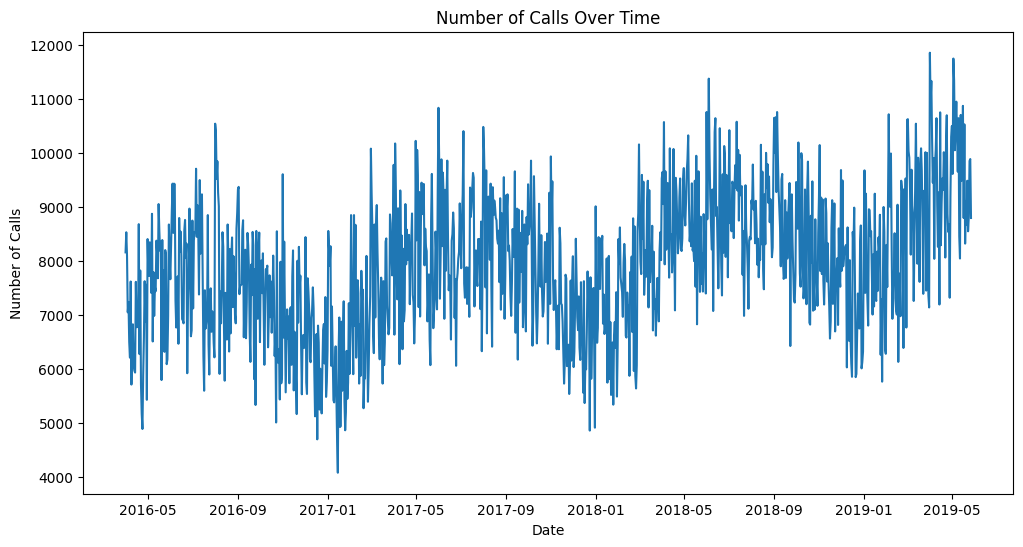

In [24]:
# Plot n_sick over time
#plt.figure(figsize=(12, 6))
#sns.lineplot(data=df, x='date', y='n_sick')
#plt.title('Number of Sick Employees Over Time')
#plt.xlabel('Date')
#plt.ylabel('Number of Sick Employees')
#plt.show()

# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='calls')
plt.title('Number of Calls Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()

# Datenvorbereitung

In [25]:
working_df = df.copy(deep=True)

print("Number NaN values:", working_df.isna().sum())

# Umgang mit fehlenden Werten
working_df = working_df.dropna()

Number NaN values: n_sick      0
calls       0
n_duty      0
n_sby       0
sby_need    0
dafted      0
dtype: int64


In [26]:
import requests 

range_of_years = range(working_df.index.year.min(), working_df.index.year.max() + 1)

german_state = 'BE' # Notfalldienst aus Berlin

holiday_dates = None

# New column for each month 
for year in range_of_years:
    url = f'https://feiertage-api.de/api/?jahr={year}&nur_land={german_state}'

    response = requests.get(url)
    holidays = response.json()

    if holiday_dates is None:
        holiday_dates = [pd.to_datetime(info['datum']) for name, info in holidays.items()]
    else:
        holiday_dates += [pd.to_datetime(info['datum']) for name, info in holidays.items()]

working_df['is_holiday'] = working_df.index.isin(holiday_dates).astype(bool)


In [27]:
import requests
import pandas as pd
from meteostat import Point, Daily
from datetime import datetime

# Definiere den Standort (Berlin)
berlin = Point(52.5200, 13.4050)

# Definiere den Zeitraum
start = datetime(working_df.index.year.min(), 1, 1)
end = datetime(working_df.index.year.max(), 12, 31)

# Lade die Wetterdaten
data = Daily(berlin, start, end)
data = data.fetch()

temperature_columns = ['tavg', "tmin", "tmax"]

# Extrahiere nur die Durchschnittstemperatur
tavg_data = data[temperature_columns]

# To-Do: Evtl mit höchste und Tiefsttemperatur arbeiten

# Füge die Durchschnittstemperatur-Spalte zum DataFrame hinzu
working_df = working_df.join(tavg_data, how='left')


In [28]:
# Feature Engineering

if True:
    working_df['year'] = working_df.index.year
    working_df['month'] = working_df.index.month
    working_df['day_of_week'] = working_df.index.dayofweek
    working_df['day_of_month'] = working_df.index.day
    working_df['week_of_year'] = working_df.index.isocalendar().week
    working_df['day_of_year'] = working_df.index.dayofyear
    working_df['is_weekend'] = working_df['day_of_week'] >= 5

    def get_season(month):
        if month in [12, 1, 2]:
            return 0 #Winter
        elif month in [3, 4, 5]:
            return 1 #Frühling
        elif month in [6, 7, 8]:
            return 2 # Sommer
        else:
            return 3 # Herbst

    working_df['season'] = working_df['month'].apply(get_season)

working_df['unix_ts_date'] = working_df.index.astype(int) // 10**9 # noch nicht ganz sicher, ob das exakt passt


working_df["needed_personal"] = working_df.apply(lambda row: (row.sby_need + row.n_duty - row.n_sick), axis=1)
working_df["calls_per_duty"] = working_df.apply(lambda row: row.calls / row.n_duty, axis=1)
working_df["call_stress"] = working_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need), axis=1)
working_df["sby_used_percent"] = working_df.apply(lambda row: (row.sby_need / row.n_sby) * 100, axis=1)

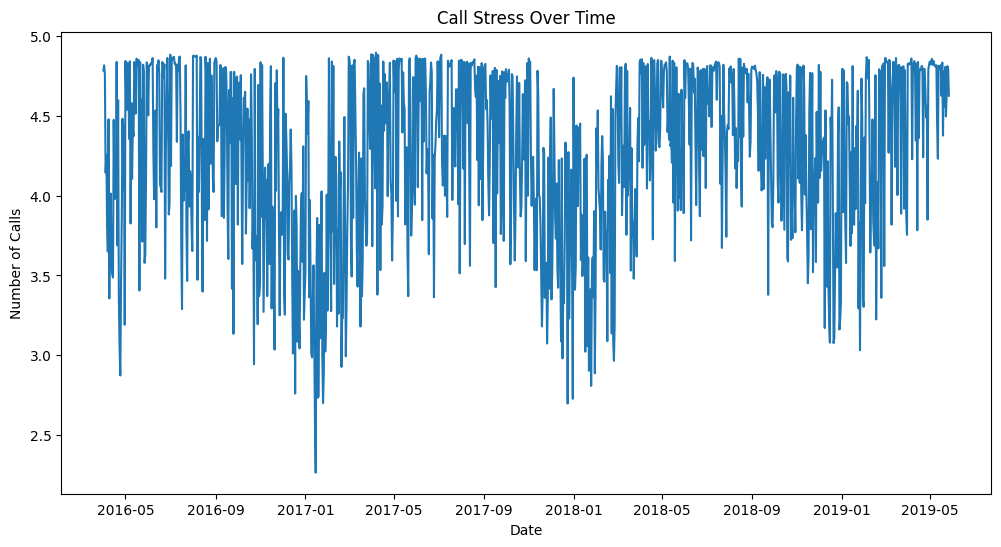

In [29]:
# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=working_df, x='date', y='call_stress')
plt.title('Call Stress Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()


# mit max 5 Calls pro verfügbare Person sollte es auskommen.
# Ziel:  Calls besser hervorsagen

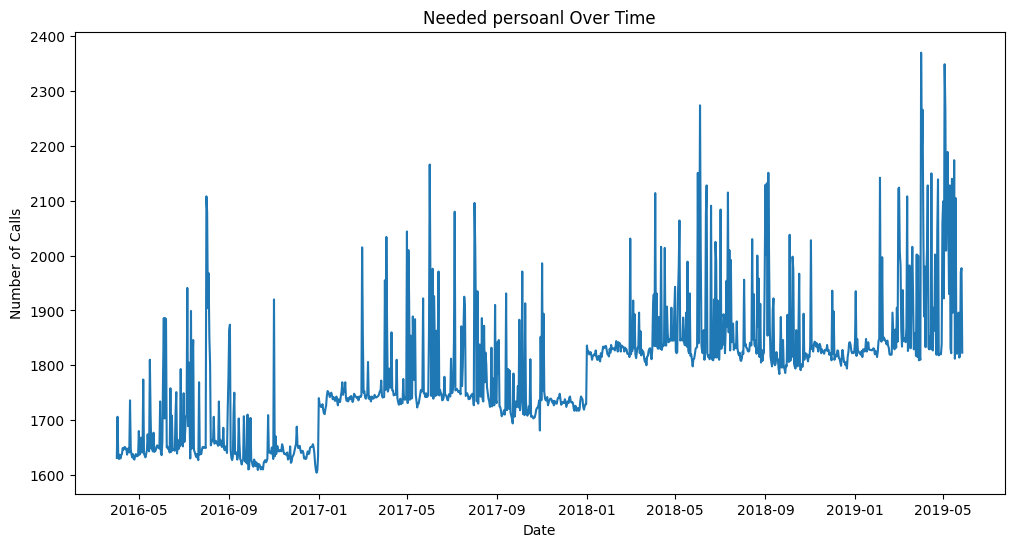

In [30]:
# Plot calls over time
plt.figure(figsize=(12, 6))
sns.lineplot(data=working_df, x='date', y='needed_personal')
plt.title('Needed persoanl Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Calls')
plt.show()


In [31]:
import warnings

if True:

    warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

    feature_list = ["calls", "n_sick", "sby_need", "calls_per_duty", "call_stress", "n_duty", "dafted"]

    for feature in feature_list:
        for i in range(0, 4):
            number_of_days = 2 ** i

            #print(f"{number_of_days =}")

            # Gleitende Durchschnitte erstellen
            working_df[f'{feature}_ma_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).mean()
            # Gleitende Mediane erstellen
            working_df[f'{feature}_median_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).median()
            # Gleitende Standardabweichungen erstellen
            working_df[f'{feature}_std_{number_of_days}'] = working_df[feature].rolling(window=number_of_days).std()

            # Lag-Features erstellen (14 Tage Schritte)
            for k in range(0, 3):  # Beispielhaft 14 Tage und 28 Tage Lag-Features
                days_in_past = 2 ** k
                print(f"{days_in_past =}")

                working_df[f'{feature}_ma_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_ma_{number_of_days}'].shift(days_in_past)
                working_df[f'{feature}_median_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_median_{number_of_days}'].shift(days_in_past)
                working_df[f'{feature}_std_{number_of_days}_lag_{days_in_past}'] = working_df[f'{feature}_std_{number_of_days}'].shift(days_in_past)

            # Drop after creating lag features
            working_df.drop(columns=[f'{feature}_ma_{number_of_days}'], inplace=True)
            working_df.drop(columns=[f'{feature}_median_{number_of_days}'], inplace=True)
            working_df.drop(columns=[f'{feature}_std_{number_of_days}'], inplace=True)

        # Entstandene NaN durch Median ersetzen (um Robustheit gegenüber Ausreißern zu gewährleisten)
        working_df = working_df.ffill().bfill()

days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_past =4
days_in_past =1
days_in_past =2
days_in_

In [32]:
pd.set_option('float_format', '{:f}'.format)
print("New dataframe:")
display(working_df)
display(working_df.describe())


display(working_df.columns)

New dataframe:


,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,tavg,tmin,tmax,...,dafted_std_4_lag_4,dafted_ma_8_lag_1,dafted_median_8_lag_1,dafted_std_8_lag_1,dafted_ma_8_lag_2,dafted_median_8_lag_2,dafted_std_8_lag_2,dafted_ma_8_lag_4,dafted_median_8_lag_4,dafted_std_8_lag_4
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.000000,1700,90,4.000000,0.000000,False,8.300000,5.000000,13.100000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2016-04-02,64,8526.000000,1700,90,70.000000,0.000000,False,9.900000,1.300000,16.400000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2016-04-03,68,8088.000000,1700,90,0.000000,0.000000,False,13.100000,6.100000,19.100000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2016-04-04,71,7044.000000,1700,90,0.000000,0.000000,False,15.200000,9.500000,20.600000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2016-04-05,63,7236.000000,1700,90,0.000000,0.000000,False,16.000000,8.400000,22.700000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-05-23,86,8544.000000,1900,90,0.000000,0.000000,False,14.200000,8.400000,19.300000,...,134.310585,56.500000,0.000000,106.674404,56.500000,0.000000,106.674404,85.500000,0.000000,119.842754
2019-05-24,81,8814.000000,1900,90,0.000000,0.000000,False,18.000000,10.600000,23.800000,...,93.500000,56.500000,0.000000,106.674404,56.500000,0.000000,106.674404,85.500000,0.000000,119.842754
2019-05-25,76,9846.000000,1900,90,146.000000,56.000000,False,13.800000,10.900000,16.300000,...,93.500000,23.375000,0.000000,66.114484,56.500000,0.000000,106.674404,56.500000,0.000000,106.674404


,n_sick,calls,n_duty,n_sby,sby_need,dafted,tavg,tmin,tmax,year,...,dafted_std_4_lag_4,dafted_ma_8_lag_1,dafted_median_8_lag_1,dafted_std_8_lag_1,dafted_ma_8_lag_2,dafted_median_8_lag_2,dafted_std_8_lag_2,dafted_ma_8_lag_4,dafted_median_8_lag_4,dafted_std_8_lag_4
count,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,...,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.000000,34.718750,16.335938,11.268229,7.051997,15.467882,2017.333333,...,21.792428,16.246311,4.040365,27.511504,16.232639,4.040365,27.485981,16.185981,4.040365,27.371081
std,14.293942,1290.063571,80.086953,0.000000,79.694251,53.394089,7.711124,6.679351,9.095201,0.977594,...,39.645365,29.624858,19.686065,38.657514,29.628722,19.686065,38.665969,29.632731,19.686065,38.649124
min,36.000000,4074.000000,1700.000000,90.000000,0.000000,0.000000,-8.800000,-12.800000,-5.800000,2016.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,58.000000,6978.000000,1800.000000,90.000000,0.000000,0.000000,5.200000,1.900000,7.900000,2017.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,68.000000,7932.000000,1800.000000,90.000000,0.000000,0.000000,10.600000,6.700000,14.950000,2017.000000,...,0.000000,1.750000,0.000000,4.949747,1.750000,0.000000,4.949747,1.750000,0.000000,4.949747
75%,78.000000,8827.500000,1900.000000,90.000000,12.250000,0.000000,17.800000,12.400000,23.000000,2018.000000,...,29.523592,23.250000,0.000000,48.399883,23.250000,0.000000,48.399883,23.156250,0.000000,48.061021
max,119.000000,11850.000000,1900.000000,90.000000,555.000000,465.000000,28.900000,23.900000,38.000000,2019.000000,...,232.500000,214.375000,194.000000,188.820729,214.375000,194.000000,188.820729,214.375000,194.000000,188.820729


Index(['n_sick', 'calls', 'n_duty', 'n_sby', 'sby_need', 'dafted',
       'is_holiday', 'tavg', 'tmin', 'tmax',
       ...
       'dafted_std_4_lag_4', 'dafted_ma_8_lag_1', 'dafted_median_8_lag_1',
       'dafted_std_8_lag_1', 'dafted_ma_8_lag_2', 'dafted_median_8_lag_2',
       'dafted_std_8_lag_2', 'dafted_ma_8_lag_4', 'dafted_median_8_lag_4',
       'dafted_std_8_lag_4'],
      dtype='object', length=275)

# Datenexport

In [33]:
working_df.to_csv("../../data/processed/sickness_table.csv")

## Kleine Modelle für Feature Importance etc

In [34]:
# Datenaufteilung
from sklearn.model_selection import train_test_split


target_column_name = "sby_need"

# Datum u. U. auch eibinden. Muss dann aber konvertiert werden

#X = working_df[['unix_ts_date', 'calls', 'n_duty', 'n_sby', 'n_sick', 'month', 'day_of_week', 'call_stress', 'calls_per_duty', 'is_holiday', 'is_weekend']] #dafted für Training weglassen, da dies direkt Aufschluss darüber gibt, dass der Wert über 100 liegt


#X = working_df[[ 'month', 'season', 'day_of_week', 'is_holiday', 'is_weekend']] #nur auf zeitliche Faktoren beschränkt

#X = working_df.loc[:, working_df.columns != target_column_name]
#X.drop(columns=['date', "sby_need", "dafted", "calls_per_duty", "calls", "call_stress", "n_sick"], inplace=True)

excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "needed_personal"]

usable_columns = list(set(working_df.columns) - set(excluded_columns))

#usable_columns = ["unix_ts_date", "is_holiday"]

X = working_df[usable_columns]


# Annahme: n_sby soll vorhergesagt werden, aber da es in der Historie fest den Wert 90 hat, kann man darauf nicht direkt predicten
# Ziel: sby_used_percent soll nahezu 100% betragen, aber nicht darüber liegen. To-Do: n_sby ausrechnen. 
# Idee: Eingabe an API mit Werten rein. Programm sagt, Warnung, die Kapazitäten werden voraussichtlich nur zu X Prozent genutzt und entsprechend wird bei n_sby dann reduziert. Im Umkehrfall bei über 100% wird erhöht
y = working_df[target_column_name]  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

## Baseline-Modell

Baseline MAE: 65.65563499113988


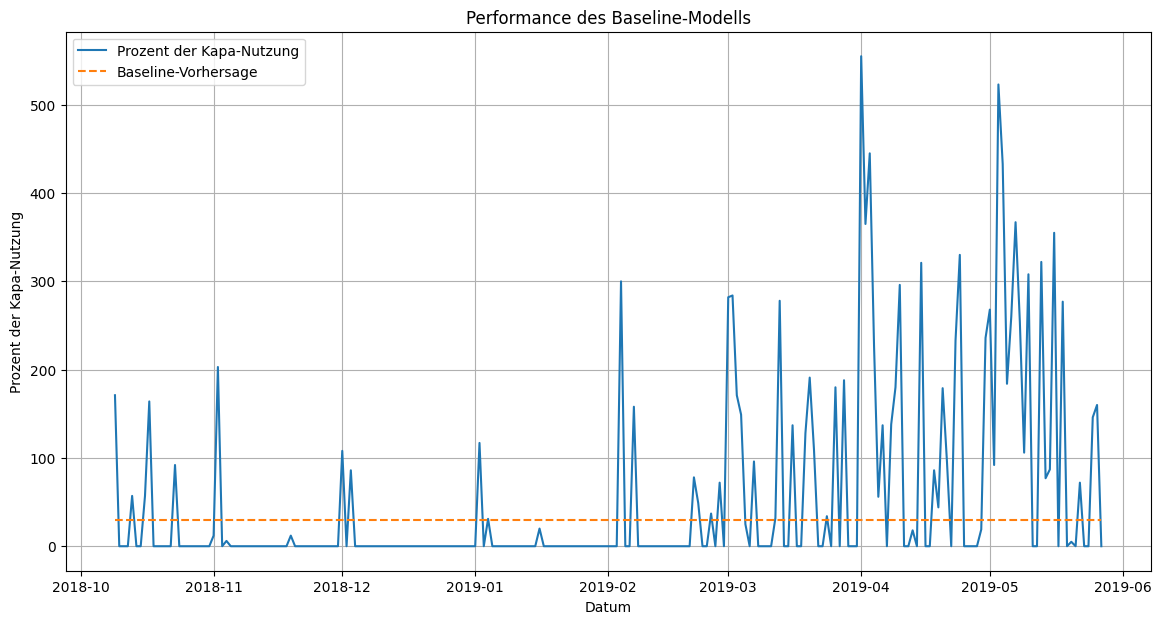

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_column_name = "sby_need"

train_size = int(len(working_df) * 0.8)
train, test = working_df.iloc[:train_size], working_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
mean_calls_train = train[target_column_name].mean()

test = test.copy() # Zum Verhindern der SettingWithCopyWarning
# Vorhersagen für das Testset mit dem Baseline-Modell
test['baseline_pred'] = mean_calls_train

# Berechnung des Mean Absolute Error (MAE) für das Baseline-Modell
mae_baseline = mean_absolute_error(test[target_column_name], test['baseline_pred'])
print(f'Baseline MAE: {mae_baseline}')

# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test.index, test[target_column_name], label='Prozent der Kapa-Nutzung')
plt.plot(test.index, test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Prozent der Kapa-Nutzung')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

## Erstellung und Evaluation des Vorhersagemodells

Model MAE: 63.719610389610395, R2 Score: 0.22777728513677087

Feature importance:
calls_per_duty_median_2_lag_1: 0.011697062412325465
tmin: 0.011890903131311643
sby_need_std_4_lag_1: 0.012337072827810646
n_sick_std_8_lag_1: 0.012684645478387466
calls_std_4_lag_4: 0.014204040938189947
n_sick_std_4_lag_2: 0.01654755163129732
tmax: 0.01920387687169182
call_stress_std_2_lag_4: 0.02038866843830991
day_of_week: 0.023503226457385774
day_of_month: 0.12823631258874146



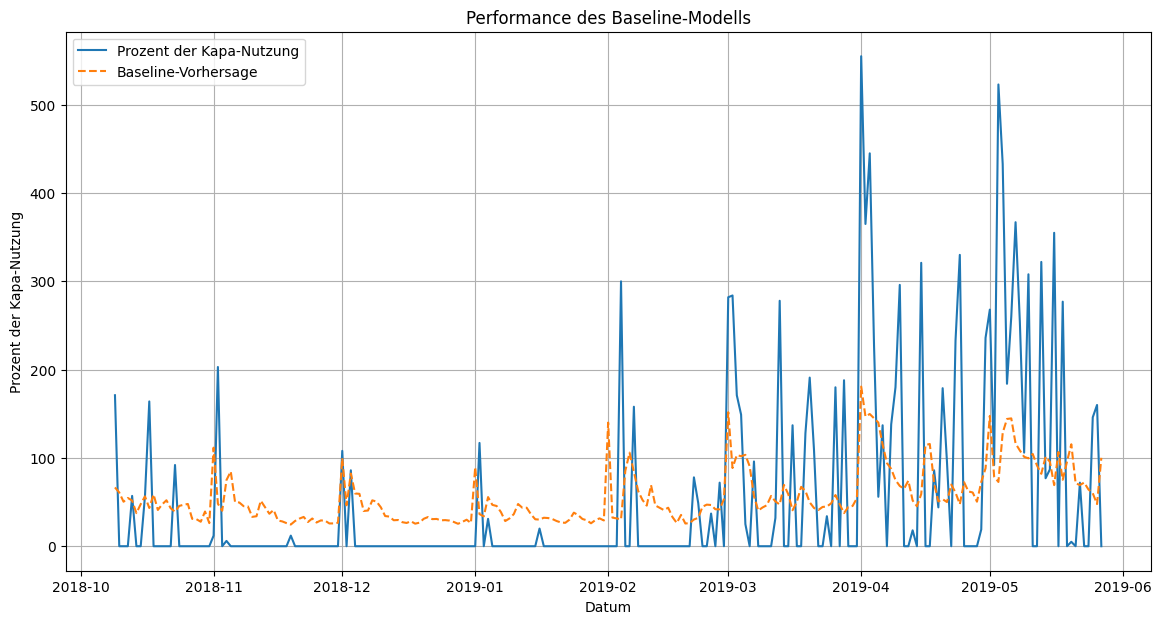

In [39]:
# Auswahl und Training eines Modells
from sklearn.ensemble import RandomForestRegressor

# Als einfacher Start. Bested Modell wird später rausgesucht
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f'Model MAE: {mean_absolute_error(y_test, y_pred)}, R2 Score: {r2_score(y_test, y_pred)}')

# Feature Importance
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)[-10:] # Top 10 Features

print("\nFeature importance:")
[print(features[i] + ":", importances[i]) for i in indices]
print("")


# Visualisierung der Performance des Baseline-Modells
plt.figure(figsize=(14, 7))
plt.plot(test.index, test[target_column_name], label='Prozent der Kapa-Nutzung')
plt.plot(test.index, test['baseline_pred'], label='Baseline-Vorhersage', linestyle='--')
plt.xlabel('Datum')
plt.ylabel('Prozent der Kapa-Nutzung')
plt.title('Performance des Baseline-Modells')
plt.legend()
plt.grid(True)
plt.show()

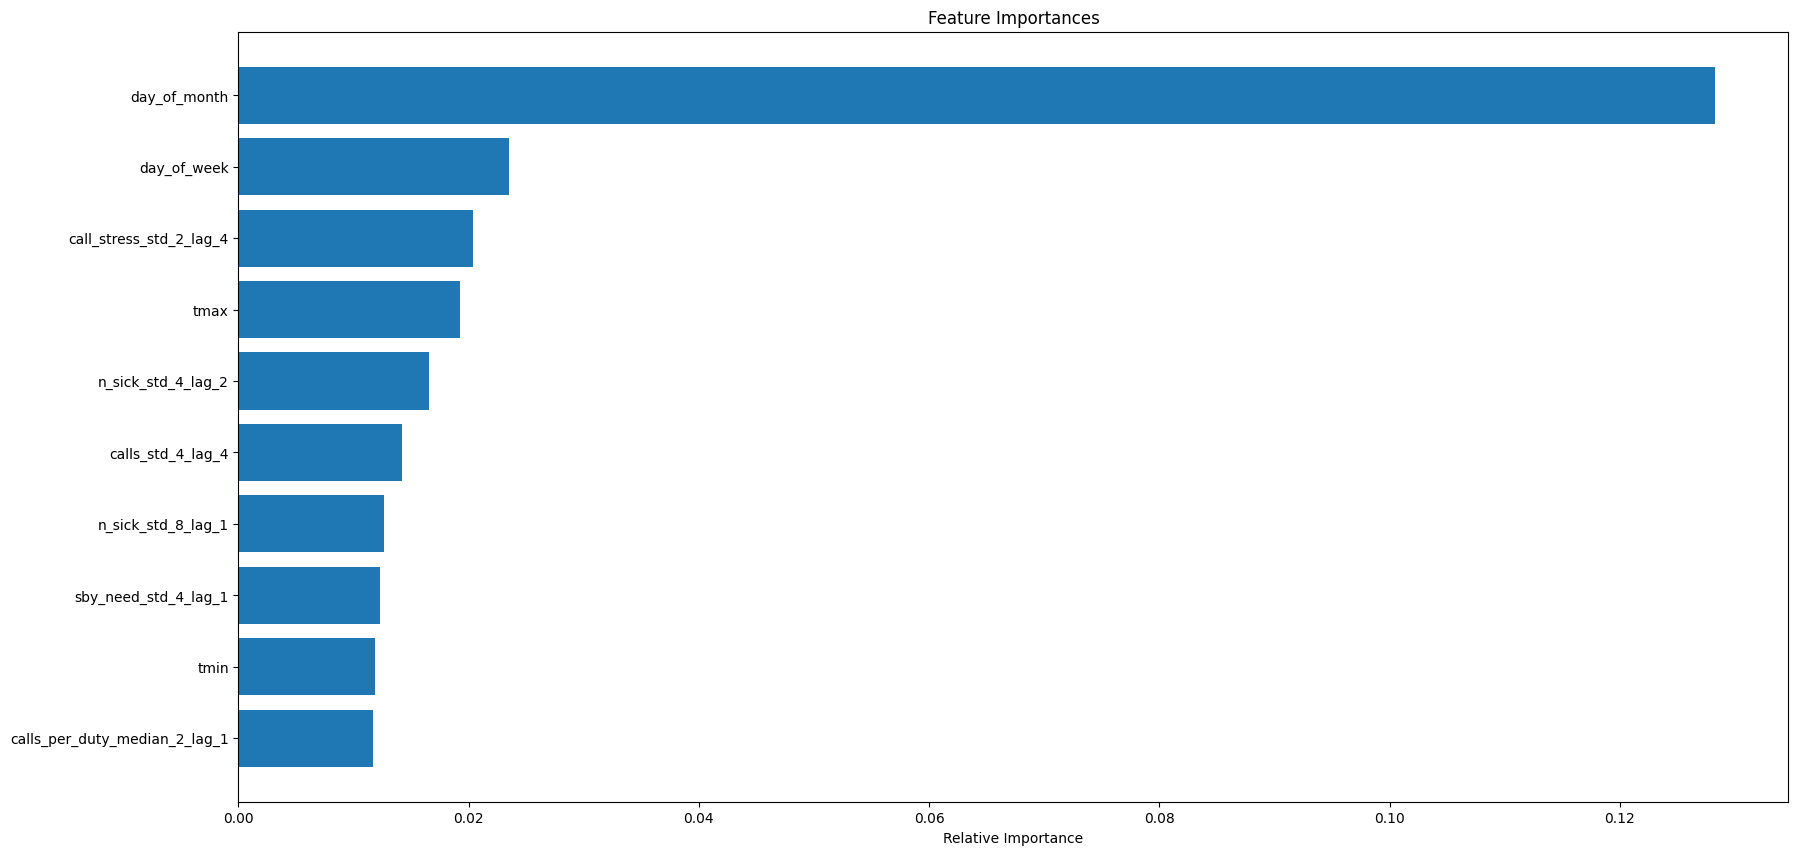

In [40]:



plt.figure(figsize=(20, 10))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

In [41]:
top_features = [features[i] for i in indices][-5:]

top_features.reverse()

display(top_features)

['day_of_month',
 'day_of_week',
 'call_stress_std_2_lag_4',
 'tmax',
 'n_sick_std_4_lag_2']

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

additional_columns = ["n_sick", "sby_need", "n_sby", "n_duty"]

X = working_df[top_features + additional_columns ]
y = working_df[target_column_name]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model.fit(X_train[top_features], y_train)

y_pred_best = model.predict(X_test[top_features])

mae = mean_absolute_error(y_test, y_pred_best)
mse = mean_squared_error(y_test, y_pred_best)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_best)
mape = mean_absolute_percentage_error(y_test, y_pred_best)

print(f'MAPE: {mape}, MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}')

MAPE: 4.205562711770441e+16, MAE: 52.124502164502175, MSE: 10466.590508225108, RMSE: 102.3063561477248, R2: 0.07418188516057234
